<span style="color:green">
Write a python method to implement a two layer network and the variable learning rate back-
propagation algorithm, with momentum.

follow equations 11.41 to 11.45 for the
forward propagation and the backpropagation of the sensitivities

VLBP is a batch algorithm, so
the gradient must be accumulated over the entire training set, as in equations 11.51 and 11.52.
Add momentum to the batch updates as in equations 12.9 and 12.10, and adjust the learning rate
and the momentum coefficient according to the three VLBP rules in Section “Variable Learning
Rate” of Chapter 12
</span>

**I didn't use any generative AI for this project.**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

# Model Classes and Functions

For multilayer backprop to work we need to define a few things:
1. activation functions as well as a way to calculate their gradient (may just be easier to predefine)
2. neuron class to handle inputs of shape R*n, this is dependant on activation functions (1)
3. layer class to handle multiple neurons in parallel for inputs of shape R,n, this is dependant on (1,2)
4. network class to handle multiple layers in series, this should have both input/output layers + hidden layers. dependant on (1,2,3)

## architecture

In [2]:
class Activation(): #base class for all activation functions
    def __init__(self,f,f_prime):
        self.f=f #activation function
        self.d=f_prime #derivative

    def __call__(self, n):
        return self.f(n)

In [3]:
# define specific activations
class Linear(Activation):
    def _linear(self,n):
        return n
    def _linear_prime(self,n):
        return np.ones_like(n)
    def __init__(self,):
        super().__init__(self._linear, self._linear_prime)

class PosLinear(Activation):
    def _poslin(self,n):
        return np.where(np.asarray(n) > 0, n, 0)
    def _poslin_prime(self,n):
        return np.where(np.asarray(n) > 0, 1, 0)
    def __init__(self,):
        super().__init__(self._poslin, self._poslin_prime)

class Sigmoid(Activation):
    def _sigmoid(self,n):
        return 1/(1+np.e**(-n))
    def _sigmoid_prime(self,n):
        return self._sigmoid(n)*(1-self._sigmoid(n))
    def __init__(self,):
        super().__init__(self._sigmoid, self._sigmoid_prime)

class GELU(Activation):
    # we use approximation, see https://onlinelibrary.wiley.com/doi/10.1155/2023/4229924 with some adjustment
    def _gelu(self, n):
        u = np.sqrt(2 / np.pi) * (n + 0.044715 * n**3)
        return 0.5 * n * (1 + np.tanh(u))

    def _gelu_prime(self, n):
        a = np.sqrt(2 / np.pi)
        u = a * (n + 0.044715 * n**3)
        t = np.tanh(u)

        return (
            0.5 * (1 + t)
            + 0.5 * n * (1 - t**2) * a
            * (1 + 3 * 0.044715 * n**2)
        )
    def __init__(self,):
        super().__init__(self._gelu, self._gelu_prime)

        


In [4]:
# i added this after conducting my network training in order to better handle classification tasks
class Hardlim(Activation):
    def _hard_limit(self, n):
        return np.where(np.asarray(n) >= 0, 1.0, 0.0)

    def _hard_limit_prime(self, n):
        return np.zeros_like(n, dtype=float) #note that this avoids where function becomes undefined

    def __init__(self):
        super().__init__(self._hard_limit, self._hard_limit_prime)

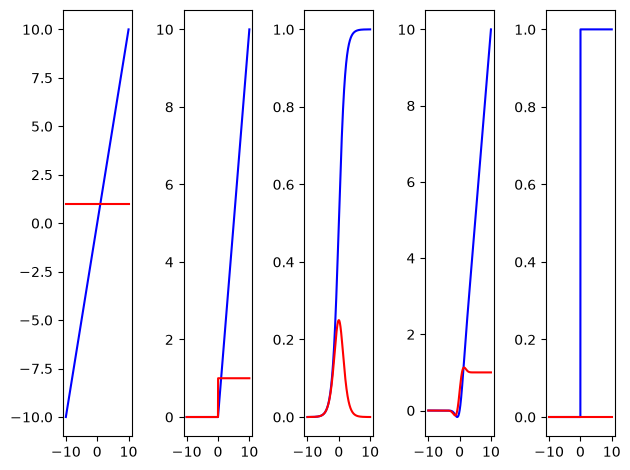

In [5]:
activations=[Linear(), PosLinear(), Sigmoid(), GELU(), Hardlim()]
x=np.linspace(-10, 10, 1000)
fig, axs=plt.subplots(1,len(activations))
for a,ax in zip(activations, axs):
    ax.plot(x,a(x), color='blue')
    ax.plot(x,a.d(x), color='red')
plt.tight_layout()
plt.show()

In [6]:
class Neuron():
    def __init__(self, weights, bias, activation:Activation): #activation should be callable, I was too lazy to do the imports for type hinting here
        weights=np.array(weights) #ensure this is array (shape = S*R where S is number of outputs, R is number of input features)
        bias=np.array(bias)

        #for single output case, reshape to 1*R
        if weights.ndim==1:
            weights=np.expand_dims(weights,axis=0)
        while bias.ndim<2:
            bias=np.expand_dims(bias,axis=1)
        
        self.W=weights
        self.S=weights.shape[0] #output features
        self.R=weights.shape[1]
        if bias.shape[0]!=self.S:
            raise ValueError(f'bias shape {bias.shape} not compatible with weight shape {weights.shape} at dim 0')
        self.b=bias
        self.activation=activation

        #lets keep track of a/n/sensitivity for each neuron in order to implement back propagation later
        self.a=0 #activation
        self.n=0 #net function input
        self.s=0 #sensitivity
        
    def __call__(self, input): # i just learned  about this underscore method and wanted to implement it for this project
        return self.forward(input)

    def forward(self, input): #this should work for batch of inputs with shape n*R
        p=np.array(input)
        if p.ndim==1: #in case of single sample, reshape to 1*R
            p = p.reshape(-1,1)
        self.n=self.W@p+self.b
        self.a=self.activation(self.n)
        return self.a

In [7]:
#sanity check
weights=[[1,0],[0,1]]
bias=[1,1]
n=Neuron(weights, bias, Linear())

#example input/output
input=[1,1]
target=np.array([[1],[1]])
out=n(input)
error=target-out
print('test 1 error',error)

#what about batch input?
inputs=np.array([input,input,input]).T
outs=n.forward(inputs)
print('test 2 output shape for 3 inputs', outs.shape) # S*n

test 1 error [[-1]
 [-1]]
test 2 output shape for 3 inputs (2, 3)


In [8]:
class Layer():
    def __init__(self, neurons:list[Neuron]|None=None, n_features:int=0, n_neurons:int=0, activation=Linear()):
        if neurons is None:
             neurons=[]
             for i in  range(n_neurons):
                 neurons.append(self._make_neuron( n_features, activation))
        if neurons is None or len(neurons)==0:
             raise ValueError('neurons not provided and random init failed')
        self.neurons=neurons

    def __call__(self, input):
            return self.forward(input)

    def _make_neuron(self, n_features:int=0, activation=None):
        n_outputs=1 # note, this could be interesting to change later
        weights = np.random.randn(1, n_features) * np.sqrt(1 / n_features) #adjusted this to ensure weights don't contain 0s
        bias = np.zeros((1, 1))
        return Neuron(weights,bias,activation)
    
    def forward(self,input):
        result=[]
        for n in self.neurons:
            a=n(input) #S*n
            result.append(a)
        #result=np.stack(result,axis=1) #NOTE: I simplified this such that the output of each layer is flattened for simplicity
        result=np.concat(result) #shape ( S*n_neurons, n). Note for this project we only really care about S=1
        return result 

In [9]:
# sanity check
l=Layer(n_features=3, n_neurons=3)
inputs=np.random.rand(3,10)
out=l(inputs) #shape = S, n
print(out.shape)

(3, 10)


In [10]:
class NeuralNet():
    def __init__(self, layers:list[Layer]|None=None, n_features:int=0, hidden_dim:int=0,n_hidden=0):
        if layers is None:
            layers=[]
            layers.append(self._make_layer(n_features,n_neurons=hidden_dim)) # input layer with n_neurons = S1 for R input features. Note each neuron produces a single output
            for i in range(n_hidden):
                layers.append(self._make_layer(hidden_dim, hidden_dim)) # hidden layers with shape S_(n-1)==S_n
            layers.append(self._make_layer(hidden_dim, 1)) #output layer shapes final hidden layer size to desired output
        if layers is None or len(layers)==0:
            raise ValueError('layers not provided and random init failed')
        self.layers=layers
        self.a0=0

    def __call__(self,input):
        return self.forward(input)
    
    def _make_layer(self,n_features:int=0, n_neurons:int=0):
        return Layer(n_features=n_features, n_neurons=n_neurons)

    def forward(self, input):
        a = np.asarray(input)
        if a.ndim == 1:
            a = a.reshape(-1, 1)
        self.a0 = a #computed on each update
        for layer in self.layers:
            a = layer(a)
        return a

    #old implementation that didn't work well
    '''
    def backward(self, error): #update sensitivities based on last batch activation (i.e. neuron n/a/s can be vectors)
        previous_s = None
        previous_W = None
        for i, layer in enumerate(reversed(self.layers)):
            s = []
            w = []
            if i > 0: #only calculate for m < M layers
                propagated = previous_W.T @ previous_s
            for j, neuron in enumerate(layer.neurons):
                if i == 0:# output layer
                    neuron.s = -2*neuron.activation.d(neuron.n)*error
                else:# hidden layers
                    neuron.s = neuron.activation.d(neuron.n)* propagated[j:j+1, :] #index j based on neurons (rows)
                s.append(neuron.s)
                w.append(neuron.W)
            previous_s = np.concatenate(s, axis=0)
            previous_W = np.concatenate(w, axis=0)

    '''
    
    def backward(self, error):
        error = np.asarray(error)

        if error.ndim == 1:
            error = error.reshape(1, -1)

        previous_s = None
        previous_W = None

        for i, layer in enumerate(reversed(self.layers)):
            derivatives = np.concatenate([neuron.activation.d(neuron.n) for neuron in layer.neurons], axis=0,)

            if i == 0: #initial sensitivity
                s = -2 * error * derivatives
            else: #backprop through hidden layers
                propagated = previous_W.T @ previous_s
                s = propagated * derivatives

            for j, neuron in enumerate(layer.neurons): #apply new sensitivities to neurons
                neuron.s = s[j:j+1, :]

            previous_W = np.concatenate([neuron.W for neuron in layer.neurons],axis=0,)
            previous_s = s

In [11]:
# sanity check (note largest sensitivity occurs at output which is what we expect)
nnet=NeuralNet(n_features=3,hidden_dim=10,n_hidden=3)
inputs=np.random.rand(3,100)
out=nnet(inputs)
print(out.shape) # S_N * n_samples
error=np.ones([1,out.shape[-1]])
nnet.backward(error)
for layer in nnet.layers:
    s=np.concat([n.s for n in layer.neurons])
    print(np.linalg.norm(s), s.shape)

(1, 100)
15.7062977389222 (10, 100)
13.235622485076082 (10, 100)
12.343818317460405 (10, 100)
15.350431967705015 (10, 100)
20.0 (1, 100)


## training

since we assign sensitivities to individual neurons we can implement multiple different optimizers. We also need a training class to implement our optimizers and networks

### optimizers

In [12]:
class Optimizer(): #base optimizer class
    def __init__(self, network:NeuralNet, learning_rate):
        self.network=network
        self.lr=learning_rate

    def __call__(self, *args, **kwds):
        self.update()

    def update(self,labels,outputs):
        raise NotImplementedError()

In [13]:
class SteepestDescent(Optimizer):
    def __init__(self, network, learning_rate):
        super().__init__(network, learning_rate)

    def update(self): #overwrite method instead of using super
        a=self.network.a0
        for layer in self.network.layers:
            next_a=[] #calculate a for this layer before updating weight
            for neuron in layer.neurons:
                next_a.append(neuron.a)
                neuron.W-=self.lr*neuron.s@a.T
                neuron.b-=self.lr*np.sum(neuron.s,keepdims=True) #sum is the same as updating for each sample in batch
            a=np.concat(next_a)

In [14]:
#sanity check using nnet from last check
optimizer=SteepestDescent(nnet,learning_rate=0.1)
optimizer()

In [15]:
#note that i initially wrote this to track momentum for each neuron, but then realized that VLBP algorithm only cares about resetting gamma
class MOBP(Optimizer):
    def __init__(self, network, learning_rate, gamma):
        super().__init__(network, learning_rate)
        self.gamma=gamma
        self._init_neurons()

    def _init_neurons(self):
        #add delta/momentum W/b parameters for each neuron
        for layer in self.network.layers:
            for neuron in layer.neurons:
                neuron.delta_W=0
                neuron.delta_b=0
                #neuron.momentum_W=0
                #neuron.momentum_b=0

    def update(self): #overwrite method instead of using super
        a=self.network.a0
        for layer in self.network.layers:
            next_a=[] #calculate a for this layer before updating weight
            for neuron in layer.neurons:
                next_a.append(neuron.a)
                dW = neuron.s @ a.T
                db = np.sum(neuron.s, axis=1, keepdims=True)

                #neuron.momentum_W=self.gamma*neuron.delta_W
                #neuron.momentum_b=self.gamma*neuron.delta_b
                neuron.delta_W = (
                    self.gamma * neuron.delta_W
                    - (1 - self.gamma) * self.lr * dW
                )
                neuron.delta_b = (
                    self.gamma * neuron.delta_b
                    - (1 - self.gamma) * self.lr * db
                )

                neuron.W += neuron.delta_W
                neuron.b += neuron.delta_b

                #update deltas/neurons
                #neuron.delta_W=neuron.momentum_W-(1-self.gamma)*self.lr*neuron.s@a.T
                #neuron.W+=neuron.delta_W
                #neuron.delta_b=neuron.momentum_b-self.lr*np.sum(neuron.s)
                #neuron.b+=neuron.delta_b #sum is the same as updating for each sample in batch

            a=np.concat(next_a)

In [16]:
#sanity check using nnet from last check
optimizer=MOBP(nnet,learning_rate=0.1, gamma=0.9)
optimizer()

### trainers

In [17]:
class Trainer(): #base trainer, no variable learning rate 
    def __init__(self, network, optimizer, n_epochs, batch_size=None):
        self.network=network
        self.optimizer=optimizer
        self.n_epochs=n_epochs
        self.batch_size=batch_size
        self.lr_log=[]

    def _update_lr(self, lr): #added this in case we need to compare optimizer lr
        self.lr_log.append(lr)

    def _epoch(self, data, labels):
        n_samples = data.shape[1]
        batch_size = self.batch_size or n_samples #let batch size be none
        loss=0

        for start in range(0, n_samples, batch_size):
            stop = min(start + batch_size, n_samples)
            # forward pass
            x=data[:,start:stop]
            y=labels[:,start:stop]
            predictions = self.network(x)
            errors=y-predictions
            batch_loss = np.mean(np.abs(errors))#MAE
            loss += batch_loss * x.shape[1] 
            # backprop
            self.network.backward(errors)
            optimizer()
        return loss/n_samples # average for all batches

    def train(self, data, labels):
        train_loss=[]
        for i in range(self.n_epochs):
            train_loss.append(self._epoch(data,labels))
        return train_loss

<span style="color:green">

1. If the squared error (over the entire training set) increases by more
than some set percentage (typically one to five percent) after a
weight update, then the weight update is discarded, the learning rate
is multiplied by some factor , and the momentum coefficient (if
it is used) is set to zero.

2. If the squared error decreases after a weight update, then the weight
update is accepted and the learning rate is multiplied by some factor
. If has been previously set to zero, it is reset to its original val-
ue.

3. If the squared error increases by less than , then the weight update
is accepted but the learning rate and the momentum coefficient are un-
changed.
</span>

In [18]:
from copy import deepcopy
class VLBP(Trainer): #inherit from original trainer class
    def __init__(self, network, optimizer:Optimizer, n_epochs, sensitivity=0.05, decrease_factor=0.1, increase_factor=1.1,verbose=False):
        #for vlbp batch size == dataset size (only update after one full epoch)
        super().__init__(network, optimizer, n_epochs)
        self.sensitivity=sensitivity
        self.decrease_factor=decrease_factor
        self.increase_factor=increase_factor
        self.verbose=verbose
        if hasattr(self.optimizer, 'gamma'):
            if self.verbose:
                print('initilizing prev gammma')
            self.optimizer.prev_gamma=self.optimizer.gamma

    def train(self, data, labels): #overwrite existing method
        train_loss=None
        for i in range(self.n_epochs):
            checkpoint = deepcopy(self.network)
            loss = self._epoch(data, labels)
            if train_loss is None:
                train_loss = [loss]
            else:
                previous_loss = train_loss[-1]
                if self.verbose: print(loss, previous_loss)
                if loss < previous_loss: #always keep weight update
                    #increase lr
                    self.optimizer.lr *= self.increase_factor
                    #re init momentum if previously 0
                    if hasattr(self.optimizer, 'gamma'):
                        if self.optimizer.gamma==0:
                            self.optimizer.gamma=self.optimizer.prev_gamma
                elif loss > (1 + self.sensitivity) * previous_loss:
                    #discard update and reduce lr
                    if self.verbose:
                        print('reloading checkpoint')
                    self.network = checkpoint
                    self.optimizer.lr *= self.decrease_factor
                    self.optimizer.network=self.network
                    loss = previous_loss # restored model corresponds to previous_loss. (commented out due to breaking convergence rules)
                    #reset momentum
                    if hasattr(self.optimizer, 'gamma'):
                        if self.verbose:
                            print('resetting momentum')
                        self.optimizer.gamma=0
                else:
                    #keep weight update but dont update momentum or lr
                    if self.verbose:
                        print(f'loss within tolerance ({loss} < {(1 + self.sensitivity) * previous_loss})')
            self._update_lr(self.optimizer.lr)
            train_loss.append(loss)
        return train_loss

# Test Problems

<span style="color:green">
Make up one or more function approximation test problems. Each student will make up their
own test problem(s), so no two test problems should be the same. The function(s) should have one
or two inputs (R = 1 or R = 2) and a single output (S2 = 1 ). In the jupyter notebook, explain how
you made up your test problem(s), and plot the function(s). Choose functions that you think will
best test the abilities of the VLBP algorithm, but make sure that the algorithm will converge within
a reasonable time.
</span>

lets go ahead and make two test datasets. One for regression on a nonlinear function, and another for classification of a problem that isn't linearly separable 

In [19]:
np.random.seed(42)

n_samples = 500
n_features=2
X = np.random.uniform(-2, 2, size=(n_features, n_samples))
x1 = X[0, :]
x2 = X[1, :]

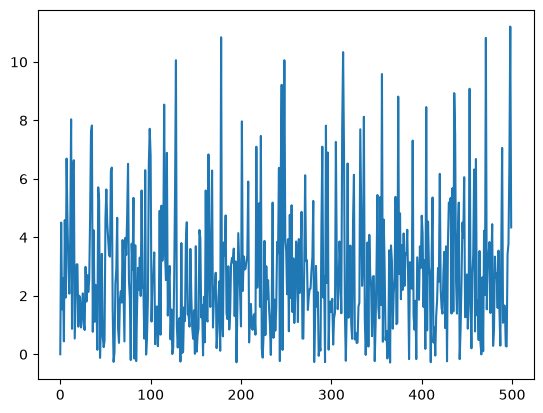

In [20]:
# nonlinear labels
y_regression = np.sin(x1) + x2**2 +x1**2 + x1 * x2
y_regression=y_regression.reshape(1,-1) # 1, n_samples

plt.figure()
plt.plot(y_regression.T)
plt.show()

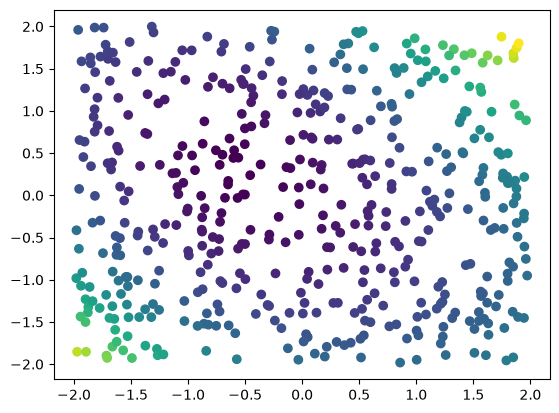

In [21]:
plt.scatter(x1,x2, c=y_regression)

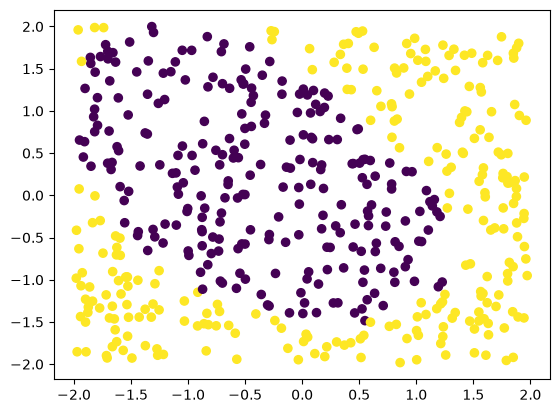

In [22]:
# convert nonlinear regression to classification
y_classification = (y_regression > np.median(y_regression)).astype(int) # this is effectively putting a loop on our data controlled by variance
y_classification = y_classification.reshape(1, -1)

plt.figure()
plt.scatter(x1, x2, c=y_classification, s=35)
plt.show()

# Prediction

<span style="color:green">
Compare VLBP with batch MOBP using a fixed learning rate. (Hint: For what values of η, ρ
and ζ does VLBP reduce to batch MOBP?) Use the same initial weights and biases and the same
convergence criterion for both algorithms, so that the comparison is fair.

state  how you expect VLBP to compare with batch
MOBP on your test problem(s), and what you expect the plot of learning rate versus iteration to
look like (for example, where you expect the learning rate to grow and where you expect it to be cut
back). Explain why. You will not be graded on whether the prediction turns out to be right. You
will be graded on the reasoning behind it, and on your explanation of any respect in which it turned
out to be wrong.
</span>

Note: ζ = sensitivity, η = lr increase factor, ρ = lr decrease factor


For this miniproject the main axis of comparison is between learning algorithms and their hyperparameters. As such we will leave the network architectures used between them the same, manipulating the number of neurons in a single hidden layer. We will manipulate the batch size and initial LR of both learning mechanisms in addition to the three VLBP hyperparams.

The prediction for this miniproject is that VLBP will mostly outperform MOBP outside the case of wildly incorrect LR. Specifically, we anticipate that VLBP will be able to recover from a poor choice of initial LR while MOBP may get stuck oscillating. VLBP should generally converge faster but may have some oscillatory behavior within the first few epochs. For  η=ρ=1 VLBP boils down to MOBP.

I'm unsure if there will be a significant difference in performance between the learning algorithms between a classification and regression problem. I believe since we aren't using cross entropy loss for back propagation the classification task will take longer to converge as it is similar to the perceptron rule such that error is binary

# Training

<span style="color:green">
Train two-layer networks to approximate the function(s), using mean square error as the per-
formance function. Begin with the VLBP parameters given in equation 12.11 (η = 1.05, ρ = 0.7
and ζ = 4%), and then try different values of η, ρ and ζ , as well as different values of the initial
learning rate and the momentum coefficient γ. (How do they interact? How sensitive is the final
result to the initial learning rate?) Also, try different numbers of neurons in the hidden layer (S1).
</span>

In [23]:
#constants for all training
learning_rates=[1e-3,1e-5, 1e-7]
batches=[500, 100, 1]
epochs=200

In [24]:
#create network
np.random.seed(42)
hidden_size=3
activation=Sigmoid() #well use this instead of gelu for now since that's what we did in class
#activation=GELU()
layers = [
    Layer( #input layer
        n_features=2,
        n_neurons=hidden_size,
        activation=activation
    ),
    Layer( #hidden layer
        n_features=hidden_size,
        n_neurons=hidden_size,
        activation=activation
    ),
    Layer( #output layer
        n_features=hidden_size,
        n_neurons=1,
        activation=Linear() #linear output for either regression or classification
    )
]
net = NeuralNet(layers=layers)

## Regression

### MOBP

for the figure below, note that runs with high LR result in some oscillatory behavior when momentum starts up. the extreme behavior in the Top left corresponds to high LR and batch size where each spike in the blue line corresponds to a new epoch and the model is trying to memorize the entire dataset.

for lr = 1e-5 and batch = 500 we see smooth behavior wherein momentum builds and initially overshoots before settling

for lr = 1e-7 we see slow progress that would require longer to converge

KeyboardInterrupt: 

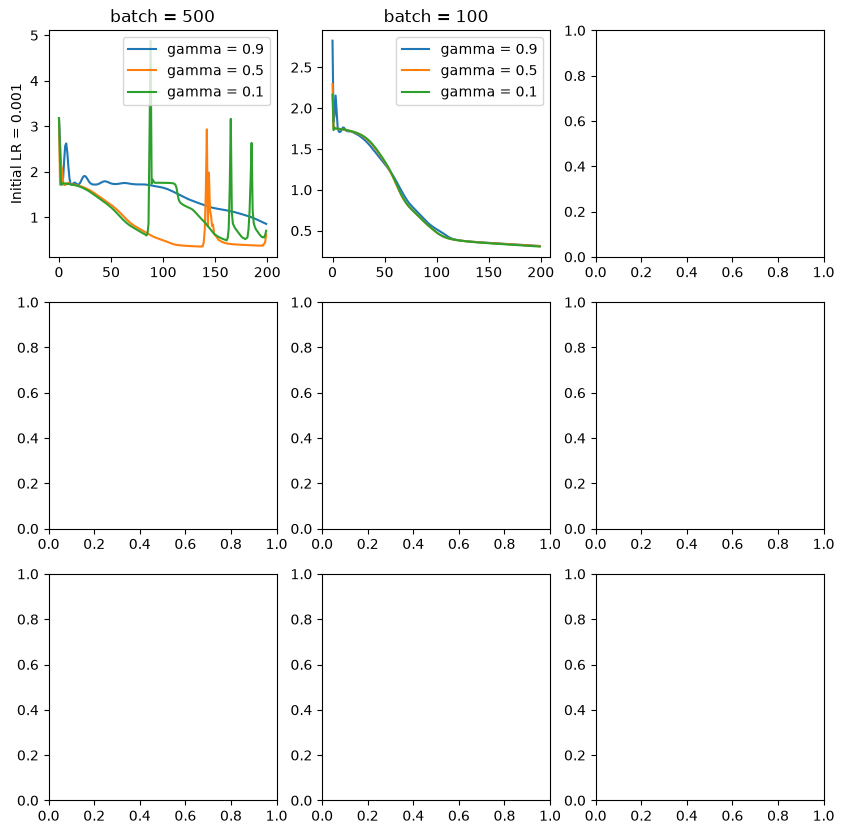

In [25]:
fig, axs=plt.subplots(len(learning_rates), len(batches),figsize=[10,10])
for i, lr in enumerate(learning_rates):
    for j,batch in enumerate(batches):
        for gamma in [0.9, 0.5, 0.1]:
            mobp_net=deepcopy(net) #use deep copy so we can directly compare runs with same initial conditions
            optimizer=MOBP(mobp_net, learning_rate=lr, gamma=gamma)
            trainer=Trainer(mobp_net, optimizer,n_epochs=epochs, batch_size=batch)
            train_loss=trainer.train(data=X, labels=y_regression)
            ax=axs[i][j]
            ax.plot(train_loss, label=f'gamma = {gamma}')
            if i==0:
                ax.set_title(f'batch = {batch}')
            if j==0:
                ax.set_ylabel(f'Initial LR = {lr}')
            ax.legend(loc='upper right')
fig.suptitle('MOBP Regression')
fig.tight_layout()
plt.show()

### VLBP

The hypothesis that VLBP alone would not perform well given a large initial lr compared to MOBP was marginally incorrect. The model exhibited stable learning so long as the lr did not increase dramatically.

The plateaus seen in some of the plots correspond to settling periods after an initial jump in predictive error due to gradually ramping up lr. This highlights why choosing appropriate hyperparameters is important and depends on your loss surface for a given problem.

As mentioned in the prediction step, for η = ρ = 1 we see our original optimization algorithm and thus lr doesn't adapt for the duration of training.

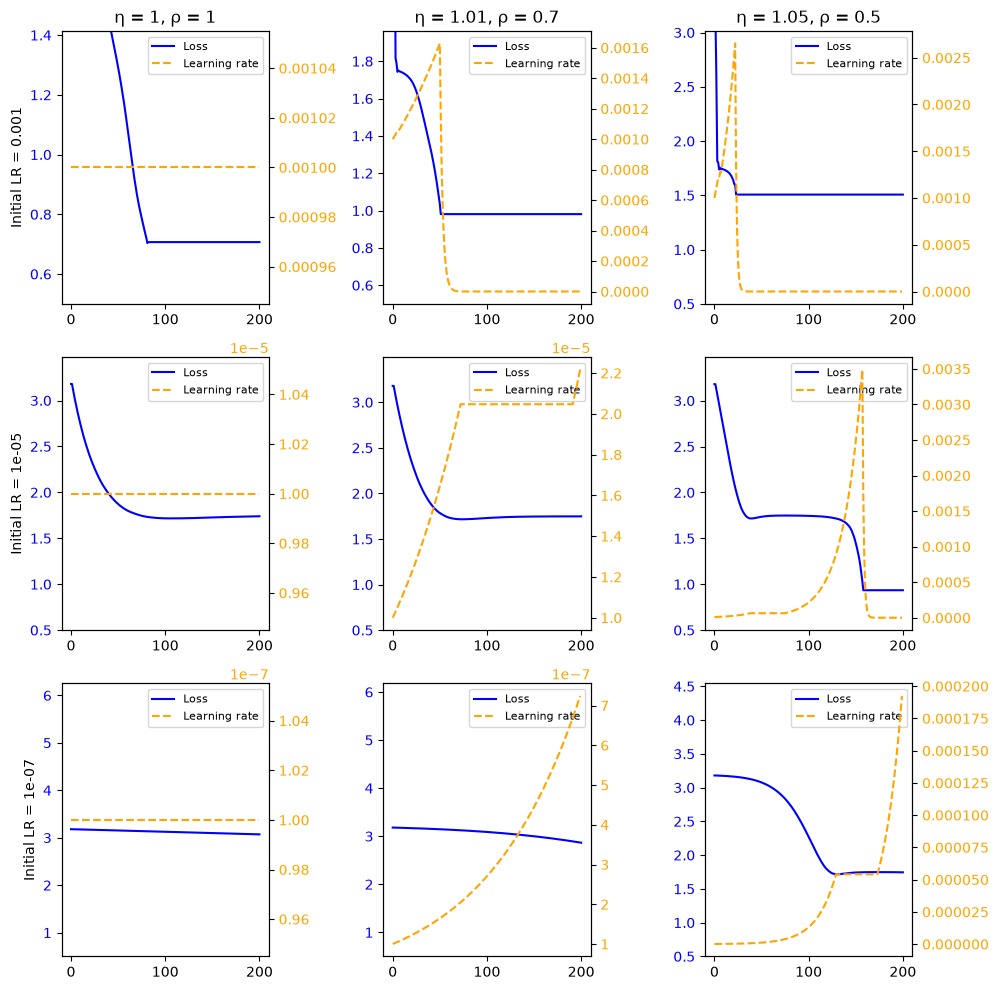

In [26]:
increases=[1, 1.01, 1.05]
decreases=[1, 0.7, 0.5]
fig, axs=plt.subplots(len(learning_rates), len(increases),figsize=[10,10])

for i,lr in enumerate(learning_rates):
    for j, (increase, decrease) in enumerate(zip(increases, decreases)):
        vlbp_net=deepcopy(net) #use deep copy so we can directly compare runs with same initial conditions
        optimizer=SteepestDescent(vlbp_net, learning_rate=lr) # need to confirm that we dont also use mobp here
        trainer=VLBP(vlbp_net, optimizer,n_epochs=epochs,
                    increase_factor=increase, decrease_factor=decrease, sensitivity=0.04, 
                    verbose=False)
        loss=trainer.train(X,y_regression)

        #plot
        ax = axs[i, j]
        #row/col header
        if i==0:
            ax.set_title(f'η = {increase}, ρ = {decrease}')
        if j==0:
            ax.set_ylabel(f'Initial LR = {lr}')
        #loss
        loss_line, = ax.plot(loss,color='blue', label='loss')
        loss_median = np.median(loss)
        ax.set_ylim(0.5, 2 * loss_median)
        ax.tick_params(axis='y', labelcolor='blue')

        # lr
        lr_ax = ax.twinx()
        lr_line, = lr_ax.plot(trainer.lr_log,color='orange',linestyle='--', label='lr')
        lr_ax.tick_params(axis='y', labelcolor='orange')
        
        #legend
        ax.legend(
            [loss_line, lr_line],
            ['Loss', 'Learning rate'],
            loc='upper right',
            fontsize=8
        )

plt.tight_layout()
plt.show()

### Combined

MOBP offers smoother learning compared to VLBP + steepest descent. However if we combine the two we can have the benefit of a large initial lr which should adapt to the gamma hyperparameter as the model learns. This behavior is exhibited by the top plots wherein oscillatory behavior is quickly mitigated by VLBP and smoother learning prevents the algorithm for resetting for a longer period of time.

Note that for smaller initial lr we observe the same benefit. Specifically for lr = 1e-7 we can see that VLBP initially ramps up until the momentum terms build enough tha

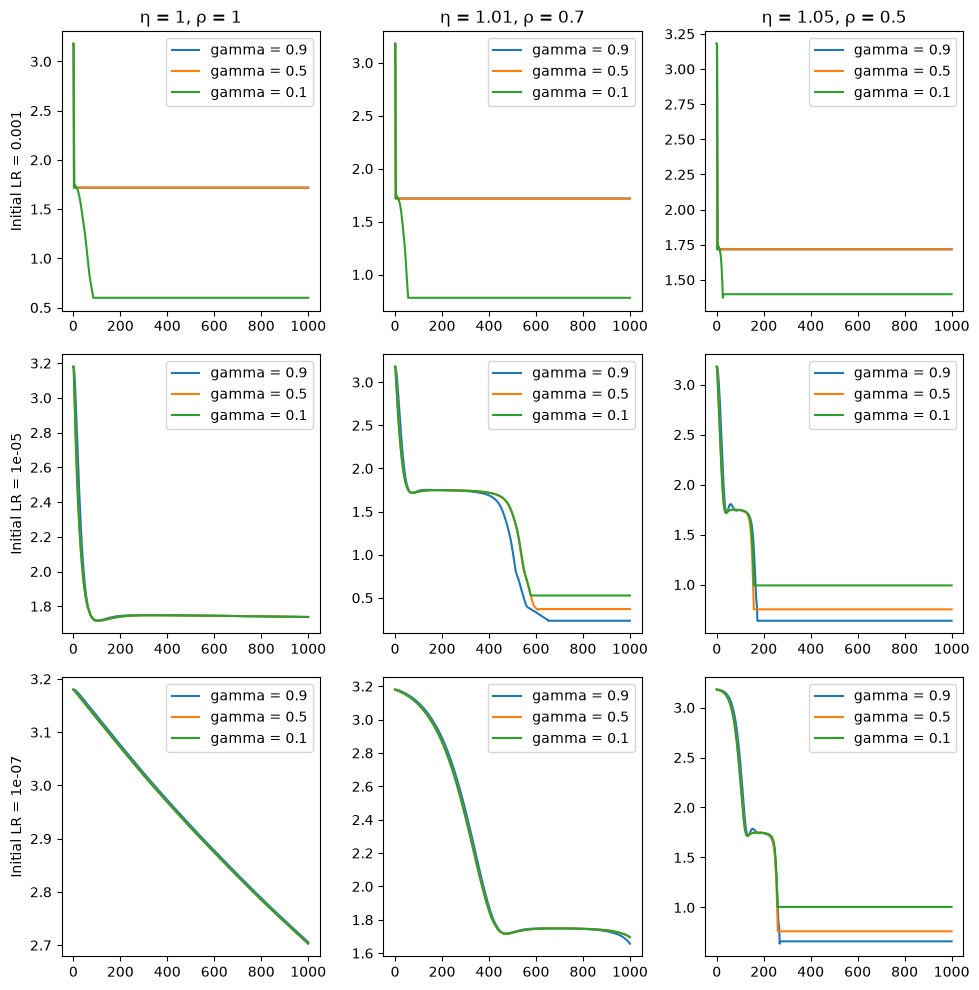

In [27]:
increases=[1, 1.01, 1.05]
decreases=[1, 0.7, 0.5]
fig, axs=plt.subplots(len(learning_rates), len(increases),figsize=[10,10])
epochs=1000 # note this is increased
for i,lr in enumerate(learning_rates):
    for j, (increase, decrease) in enumerate(zip(increases, decreases)):
        for gamma in [0.9, 0.5, 0.1]:
            combined_net=deepcopy(net) #use deep copy so we can directly compare runs with same initial conditions
            optimizer=MOBP(combined_net, learning_rate=lr, gamma=gamma) # need to confirm that we dont also use mobp here
            trainer=VLBP(combined_net, optimizer,n_epochs=epochs,
                        increase_factor=increase, decrease_factor=decrease, sensitivity=0.04, 
                        verbose=False)
            loss=trainer.train(X,y_regression)

            #plot
            ax = axs[i, j]
            #row/col header
            if i==0:
                ax.set_title(f'η = {increase}, ρ = {decrease}')
            if j==0:
                ax.set_ylabel(f'Initial LR = {lr}')
            ax.plot(loss, label=f'gamma = {gamma}')
            
        #legend
        ax.legend()
plt.tight_layout()
plt.show()

## Classification

The plots in this section follow the same trends as the regression problem. However we observe that convergence occurs much faster. This is likely due to our hypothesis being correct, that a binary classification problem is generally easier compared to a regression problem of similar complexity.

### MOBP

In [ ]:
#reset epochs from last section
epochs=200

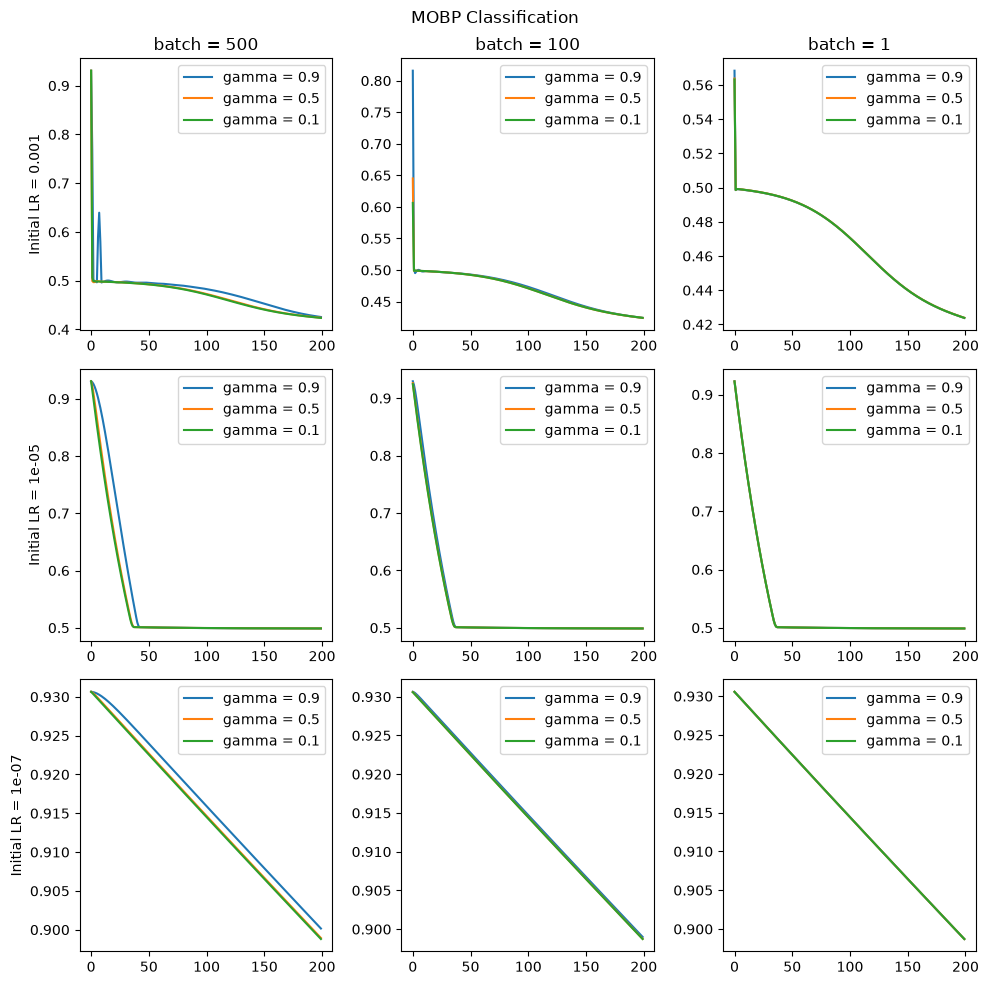

In [ ]:
fig, axs=plt.subplots(len(learning_rates), len(batches),figsize=[10,10])
for i, lr in enumerate(learning_rates):
    for j,batch in enumerate(batches):
        for gamma in [0.9, 0.5, 0.1]:
            mobp_net=deepcopy(net) #use deep copy so we can directly compare runs with same initial conditions
            optimizer=MOBP(mobp_net, learning_rate=lr, gamma=gamma)
            trainer=Trainer(mobp_net, optimizer,n_epochs=epochs, batch_size=batch)
            train_loss=trainer.train(data=X, labels=y_classification)
            ax=axs[i][j]
            ax.plot(train_loss, label=f'gamma = {gamma}')
            if i==0:
                ax.set_title(f'batch = {batch}')
            if j==0:
                ax.set_ylabel(f'Initial LR = {lr}')
            ax.legend(loc='upper right')
fig.suptitle('MOBP Classification')
fig.tight_layout()
plt.show()

### VLBP

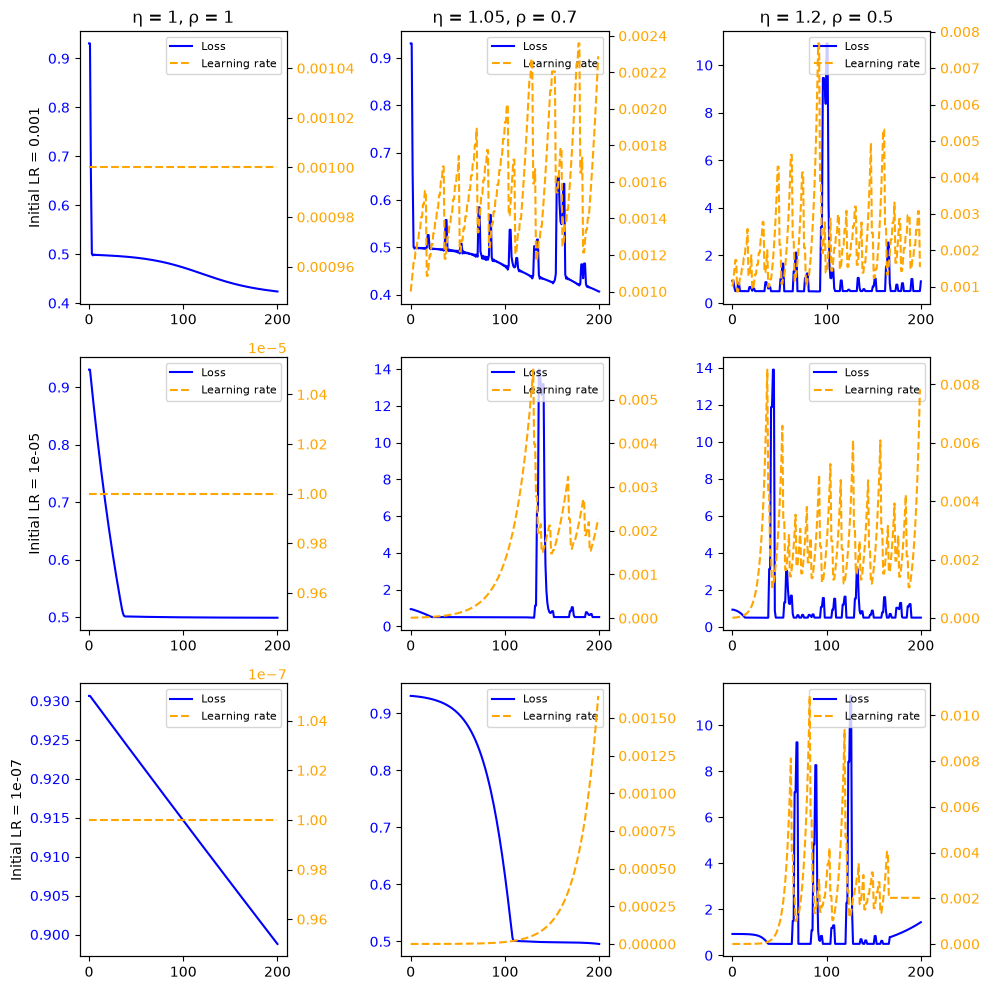

In [ ]:
increases=[1, 1.05, 1.2]
decreases=[1, 0.7, 0.5]
fig, axs=plt.subplots(len(learning_rates), len(increases),figsize=[10,10])

for i,lr in enumerate(learning_rates):
    for j, (increase, decrease) in enumerate(zip(increases, decreases)):
        vlbp_net=deepcopy(net) #use deep copy so we can directly compare runs with same initial conditions
        optimizer=SteepestDescent(vlbp_net, learning_rate=lr) # need to confirm that we dont also use mobp here
        trainer=VLBP(vlbp_net, optimizer,n_epochs=epochs,
                    increase_factor=increase, decrease_factor=decrease, sensitivity=0.04, 
                    verbose=False)
        loss=trainer.train(X,y_classification)

        #plot
        ax = axs[i, j]
        #row/col header
        if i==0:
            ax.set_title(f'η = {increase}, ρ = {decrease}')
        if j==0:
            ax.set_ylabel(f'Initial LR = {lr}')
        #loss
        loss_line, = ax.plot(loss,color='blue', label='loss')
        loss_median = np.median(loss)
        #ax.set_ylim(0.5, 2 * loss_median)
        ax.tick_params(axis='y', labelcolor='blue')

        # lr
        lr_ax = ax.twinx()
        lr_line, = lr_ax.plot(trainer.lr_log,color='orange',linestyle='--', label='lr')
        lr_ax.tick_params(axis='y', labelcolor='orange')
        
        #legend
        ax.legend(
            [loss_line, lr_line],
            ['Loss', 'Learning rate'],
            loc='upper right',
            fontsize=8
        )

plt.tight_layout()
plt.show()

### Combined

/tmp/ipykernel_43052/631651170.py:20: RuntimeWarning: overflow encountered in power
  return 1/(1+np.e**(-n))


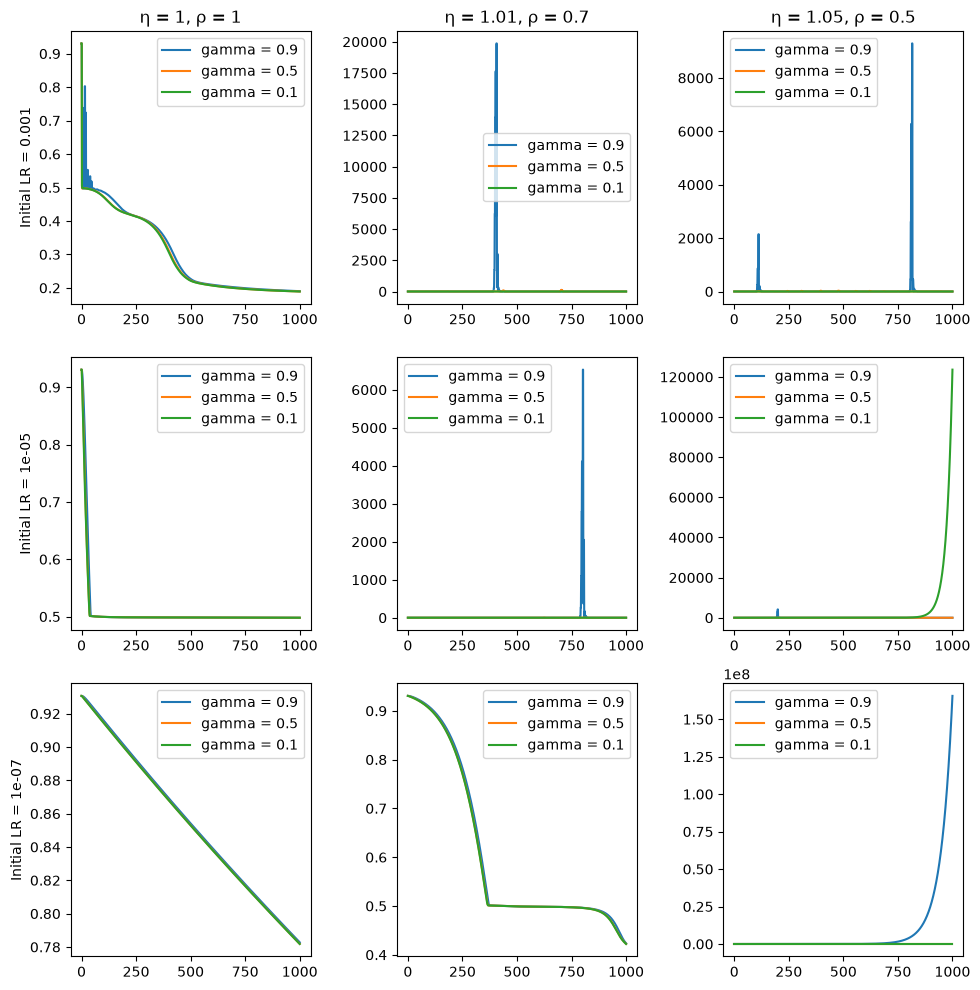

In [ ]:
increases=[1, 1.01, 1.05]
decreases=[1, 0.7, 0.5]
fig, axs=plt.subplots(len(learning_rates), len(increases),figsize=[10,10])
epochs=1000 # note this is increased
for i,lr in enumerate(learning_rates):
    for j, (increase, decrease) in enumerate(zip(increases, decreases)):
        for gamma in [0.9, 0.5, 0.1]:
            combined_net=deepcopy(net) #use deep copy so we can directly compare runs with same initial conditions
            optimizer=MOBP(combined_net, learning_rate=lr, gamma=gamma) # need to confirm that we dont also use mobp here
            trainer=VLBP(combined_net, optimizer,n_epochs=epochs,
                        increase_factor=increase, decrease_factor=decrease, sensitivity=0.04, 
                        verbose=False)
            loss=trainer.train(X,y_classification)

            #plot
            ax = axs[i, j]
            #row/col header
            if i==0:
                ax.set_title(f'η = {increase}, ρ = {decrease}')
            if j==0:
                ax.set_ylabel(f'Initial LR = {lr}')
            ax.plot(loss, label=f'gamma = {gamma}')
            
        #legend
        ax.legend()
plt.tight_layout()
plt.show()

## Final investigations

lets look at effect of increasing network complexity using combined MOBP + VLBP

In [28]:
#reset epochs from last section
epochs=1000

In [29]:
def create_network(hidden_size, n_hidden_layers, activation=Sigmoid()):
    #create network
    np.random.seed(42)
    input =[ 
        Layer( #input layer
            n_features=2,
            n_neurons=hidden_size,
            activation=activation
        )
    ]
    hidden=[
        Layer( #hidden layer
            n_features=hidden_size,
            n_neurons=hidden_size,
            activation=activation
        )
        for _ in range(n_hidden_layers)
    ]
    
    output=[
        Layer( #output layer
            n_features=hidden_size,
            n_neurons=1,
            activation=Linear() #linear output for either regression or classification
        )
    ]
    return NeuralNet(layers=input+hidden+output)

We can observe that increasing network complexity generally increases the amount of time required to fit the model. For this problem we see that a shallow but wide network fits well and adding additional layers doesn't result in much of a performance gain

The prediction plot indicates that the model doesn't fit well until after the first 500 epochs are up. This behavior fits what we observed in class where the model parameters "snapped" into place after the first few epochs.

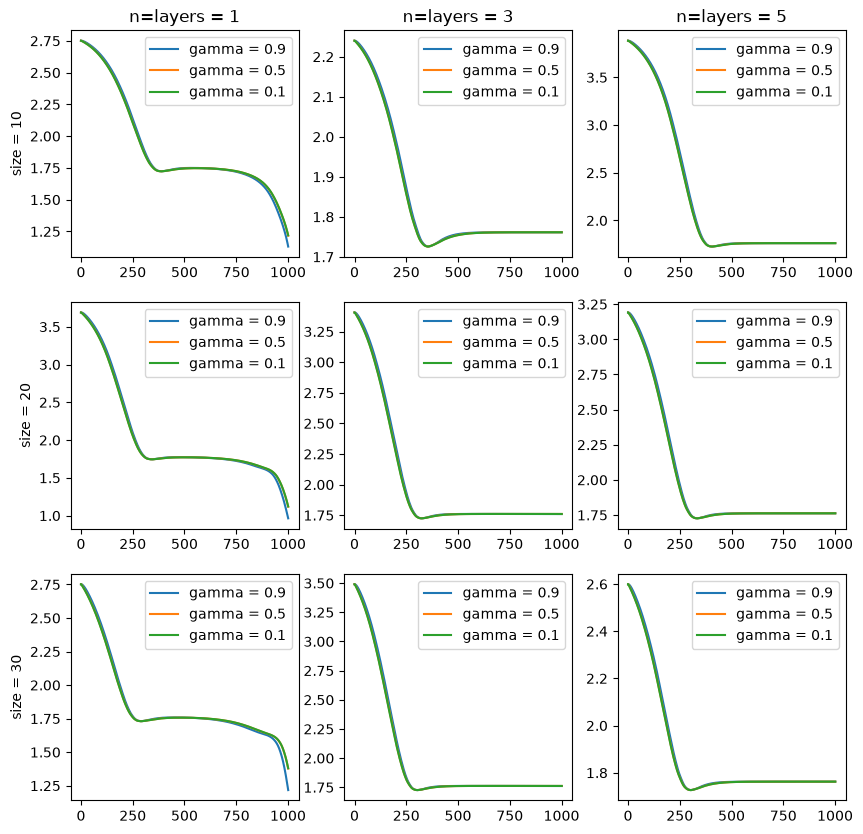

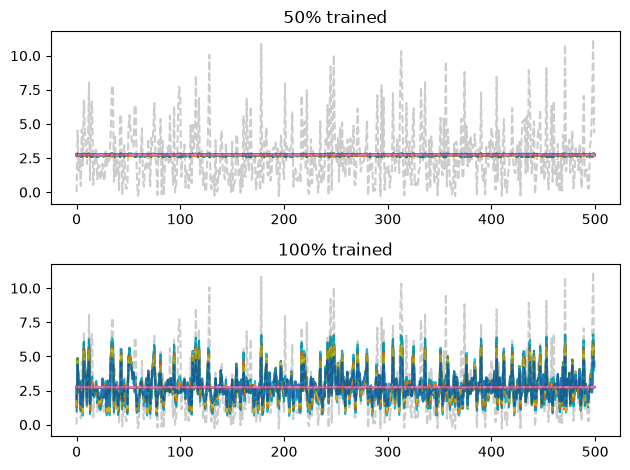

In [30]:
hidden_sizes=[10,20,30]
n_hidden=[1,3,5]
# lets use our best guess from preliminary grid search in previous section
decrease=0.7
increase=1.01
lr=1e-7
fig, axs=plt.subplots(len(hidden_sizes), len(n_hidden),figsize=[10,10])
fig2, axs2=plt.subplots(2,1)
for i, size in enumerate(hidden_sizes):
    for j, n_layers in enumerate(n_hidden):
        for gamma in [0.9, 0.5, 0.1]:
            net=create_network(size,n_layers)
            optimizer=MOBP(net, learning_rate=lr, gamma=gamma) # need to confirm that we dont also use mobp here
            trainer=VLBP(net, optimizer,n_epochs=epochs//2, #adjusted epochs  for two training sessions
                        increase_factor=increase, decrease_factor=decrease, sensitivity=0.04, 
                        verbose=False)
            loss=[]
            #train in two batches maintaining network and optimizer state between them:
            for k in range(2):
                loss.extend(trainer.train(X,y_regression))
                prediction=trainer.network(X)
                axs2[k].plot(prediction.T)
            ax = axs[i, j]
            ax.plot(loss, label=f'gamma = {gamma}')
        #row/col header
        if i==0:
            ax.set_title(f'n=layers = {n_layers}')
        if j==0:
            ax.set_ylabel(f'size = {size}')
            
        #legend
        ax.legend()

plt.tight_layout()

#prediction plot
for ax in axs2:
    ax.plot(y_regression.T, color='black', alpha=0.2, linestyle='--')
axs2[0].set_title('50% trained')
axs2[1].set_title('100% trained')

plt.tight_layout()
plt.show()

lets hypothesize that performance improves for classification

Again we see that for our problem set/network architecture, shallow networks are more performant. This may be due to vanishing gradients for deeper networks

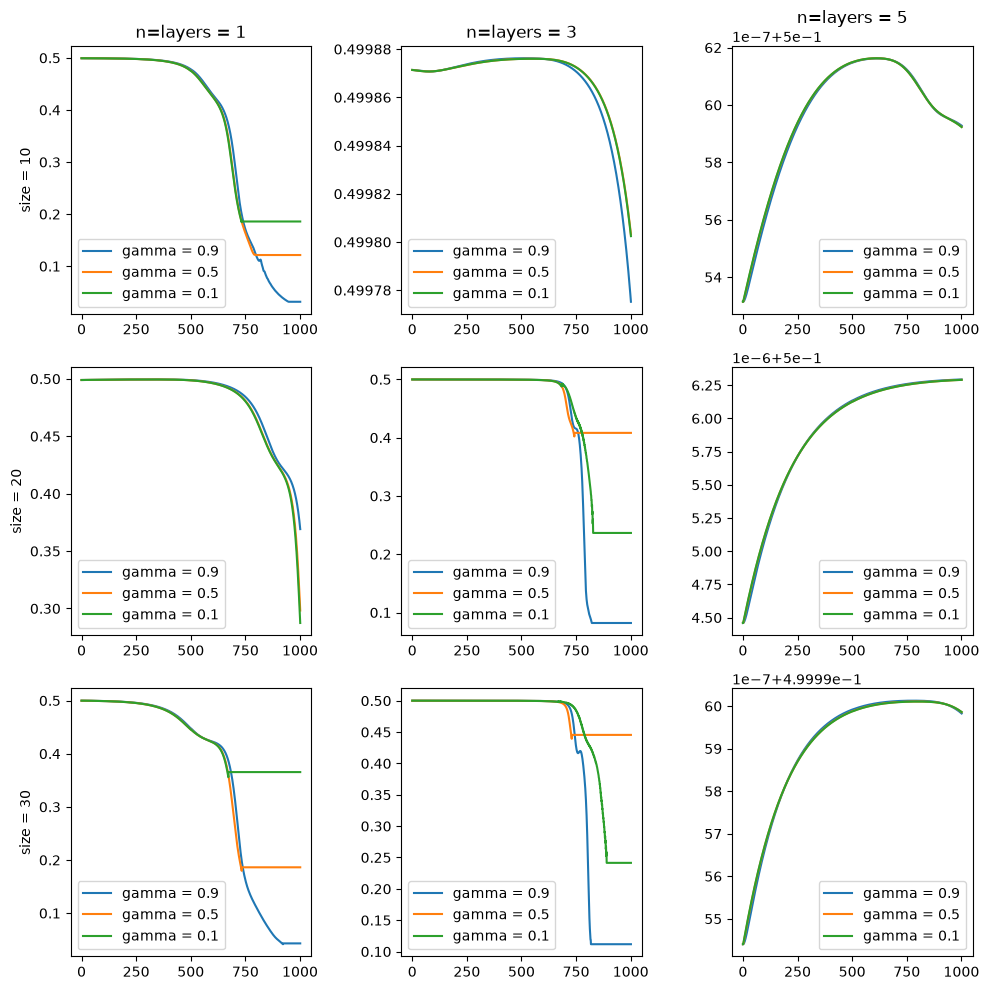

In [31]:
hidden_sizes=[10,20,30] #increased size
n_hidden=[1,3,5]
# lets use our best guess from preliminary grid search in previous section
decrease=0.7
increase=1.01
lr=1e-5
fig, axs=plt.subplots(len(hidden_sizes), len(n_hidden),figsize=[10,10])
predictions=[]
for i, size in enumerate(hidden_sizes):
    for j, n_layers in enumerate(n_hidden):
        for gamma in [0.9, 0.5, 0.1]:
            net=create_network(size,n_layers)
            for l in net.layers:
                for n in l.neurons:
                    n.activation=Sigmoid() #adjusted for class
            optimizer=MOBP(net, learning_rate=lr, gamma=gamma) # need to confirm that we dont also use mobp here
            trainer=VLBP(net, optimizer,n_epochs=epochs//2, #adjusted epochs  for two training sessions
                        increase_factor=increase, decrease_factor=decrease, sensitivity=0.04, 
                        verbose=False)
            loss=[]
            prediction={'layer size':size,
                        'n-layers':n_layers,
                        'gamma':gamma,
                        'values':[]
                        }
            #train in two batches maintaining network and optimizer state between them:
            for k in range(2):
                loss.extend(trainer.train(X,y_classification))
                prediction['values'].append(trainer.network(X))
            predictions.append(prediction)
            ax = axs[i, j]
            ax.plot(loss, label=f'gamma = {gamma}')
        #row/col header
        if i==0:
            ax.set_title(f'n=layers = {n_layers}')
        if j==0:
            ax.set_ylabel(f'size = {size}')
            
        #legend
        ax.legend()

plt.tight_layout()
plt.show()

we can observe in  the model predictions that a nonlinear boundary is drawn over our data for models with good performance

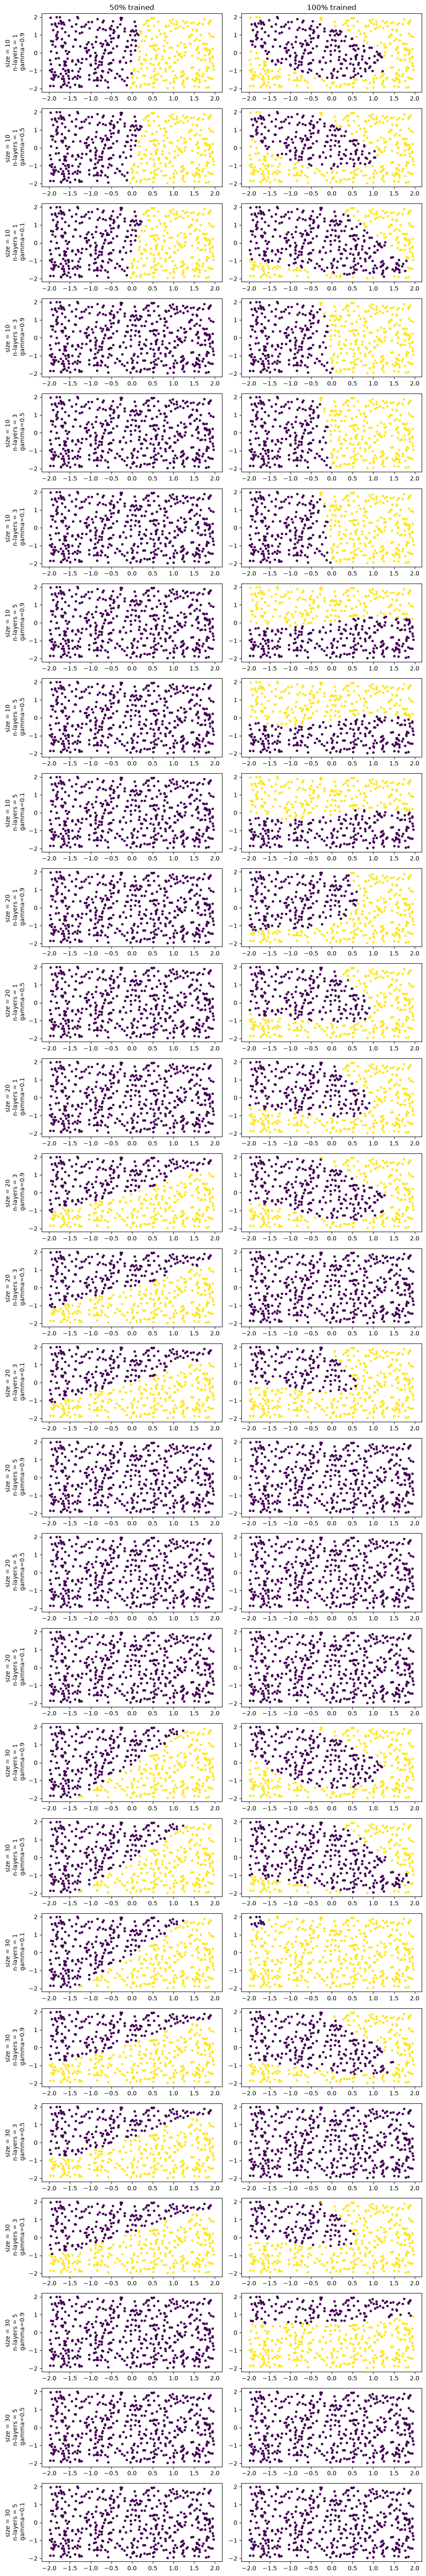

In [32]:
fig, axs=plt.subplots(len(predictions),2, figsize=[10,60])
for i,pred in enumerate(predictions):
    for j, values in enumerate(pred['values']):
        ax=axs[i][j]
        ax.scatter(x1,x2,c=np.where(values>0.5,1,0),s=10)
        if i==0:
            if j==0:
                ax.set_title('50% trained')
            elif j==1:
                ax.set_title('100% trained')
        if j==0:
            ax.set_ylabel(f'size = {pred['layer size']} \n n-layers = {pred['n-layers']} \n gamma={pred['gamma']}')
plt.tight_layout()
plt.show()

what if we change the activation function on the output to limit the network response?

In [33]:
def set_output_activation(net: NeuralNet, activation:Activation):
    for layer in net.layers:
        for n in layer.neurons:
            n.activation=activation
    return net

we observe the model never learns with hardlim. This matches what we saw in class since the derivative is 0 and this prevents loss from back propagating

The sigmoid layer looks to have greatly improved performance. This is due to outputs being constrained between 0-1

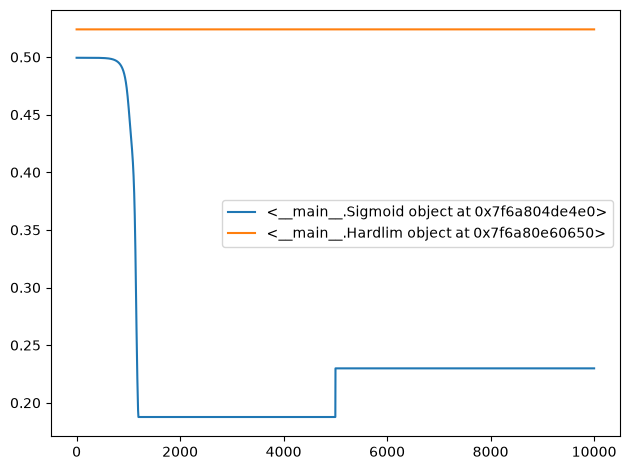

In [34]:
epochs=10000
# lets use our best guess from preliminary grid search in previous section
decrease=0.7
increase=1.01
lr=1e-7
plt.figure()
#from best performance architectures
size=10
n_layers=1
predictions=[]
gamma=0.1
for i,activation in enumerate([Sigmoid(), Hardlim()]):
    net=create_network(size,n_layers)
    net=set_output_activation(net,activation)
    optimizer=MOBP(net, learning_rate=lr, gamma=gamma) # need to confirm that we dont also use mobp here
    trainer=VLBP(net, optimizer,n_epochs=epochs//2, #adjusted epochs  for two training sessions
                increase_factor=increase, decrease_factor=decrease, sensitivity=0.04, 
                verbose=False)
    loss=[]
    prediction={'activation':activation,
                'values':[]
                }
    #train in two batches maintaining network and optimizer state between them:
    for k in range(2):
        loss.extend(trainer.train(X,y_classification))
        prediction['values'].append(trainer.network(X))
    predictions.append(prediction)
    plt.plot(loss, label=activation)

plt.legend()
plt.tight_layout()
plt.show()

We can see even after only 50% of our training epochs the model has fit to the data well. For future development we would want to implement early stopping as a form of regularization in addition to a validation set.

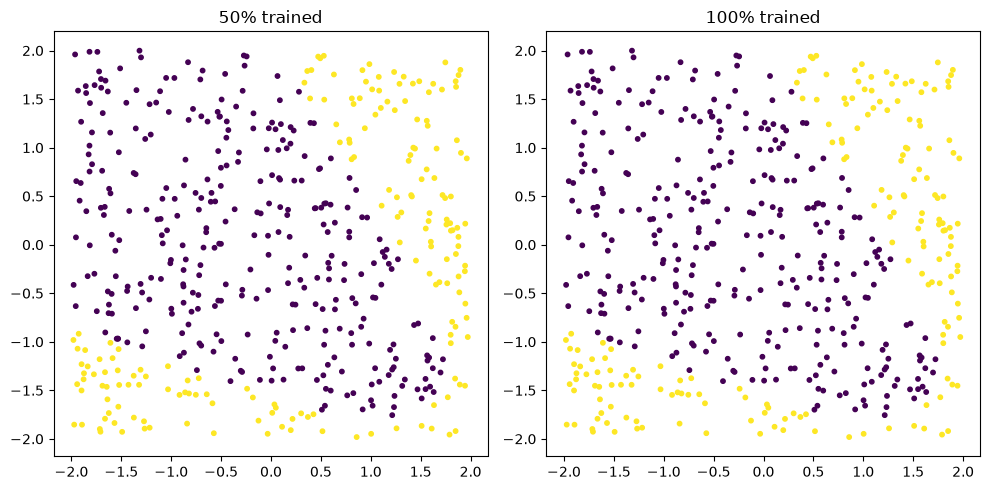

In [35]:
fig, axs=plt.subplots(1,2, figsize=[10,5])
for i,pred in enumerate(predictions):
    for j, values in enumerate(pred['values']):
        ax=axs[j]
        ax.scatter(x1,x2,c=np.where(values>0.5,1,0),s=10)
        if i==0:
            if j==0:
                ax.set_title('50% trained')
            elif j==1:
                ax.set_title('100% trained')
    break #lets ignore the hardlim attempt
plt.tight_layout()
plt.show()

In [36]:
#count total number of trainable parameters
net=create_network(size,n_layers)
n_params=0
for layer in net.layers:
    for n in layer.neurons:
        n_params+=n.W.shape[0]*n.W.shape[1]+n.b.shape[0]*n.b.shape[1]
print(n_params)

151


# Discussion

<span style="color:green">
Investigate different properties of the network that might affect convergence (e.g., size of initial
weights). Watch how the learning rate changes during training. When does it increase, when
does it decrease, and how does this relate to the shape of the performance surface? This is an
open-ended problem, so follow your intuition to learn as much as you can about variable learning
rate backpropagation and explain the results of your exploration.
</span>

<span style="color:green">

discuss the following
- Discussion of how you came up with the test problem(s)
- Discussion of the results you obtained in your tests. Discuss the effects of changing the
number of neurons, the VLBP parameters (η, ρ, ζ ), the initial learning rate and the momentum
coefficient. Compare the convergence of VLBP and batch MOBP. What did you learn from
doing this project? The discussion is the most important part of the miniproject. In addition
to tables, plots and code, explain what you did in each part and what you learned from your
experiments.
- Plots of sum-squared error (over entire training set) versus iteration number, and of learning
rate versus iteration number, for each run (as in Figure 12.12, but use a log-log scale for the
sum-squared error). Since VLBP computes the sum-squared error at every iteration, you can
record it at every iteration
- A table summarizing, for each run, the number of iterations to convergence, the number of
rejected weight updates and the final sum-squared error
- Plots of the network function and actual function at two stages of the training (i.e., midway
through training and at the completion of training). Use +’s to indicate the points from the
training set, as in Figure 11.15. The true function and network function plots should be
computed at a fine grid, so that they appear continuous, as in Figure 11.15. Be sure that when
you compute the network function you use the same weights and biases for all values of
p. You only need to make these plots for one set of VLBP parameters, but for a couple of
different numbers of hidden neurons.
- A Prediction section, placed before your results, as described above.
- At least one experiment that did not come out the way you expected, together with your
explanation of what happened. This can be a bug you had to track down, a result that
2
contradicted your prediction, or a comparison that showed no difference where you expected
one. Do not delete your dead ends. They are worth more to me than another plot that works

</span>

*general observations*

Initial learning rate is a primary driver of whether or not model training converges regardless of which optimization algorithm we choose. In general, LR needs to be selected alongside other hyperparameters simultaneously. This becomes problematic as seen in our various grid searches as multiple networks must be trained over and over again to determine an appropriate configuration. Future work here may include implementation of Bayesian hyperparameter estimation such that we can efficiently search the hyperparameter space without needing to fully train models on sets of hyperparameters that won't work well.

The momentum parameter gamma was shown to help smooth our convergence rate out and was especially powerful when using a small batch size. Since VLBP requires a full pass through our dataset this behavior was seen to help the model reconvene when LR was increased.

VLBP parameters were important with respect to initial learning rate. A large initial LR was useful since the algorithm could slow it down. However if the decay rate wasn't aggressive enough the model was likely to be caught in a local minima where performance was poor. Combined with MOBP this weakness was mitigated. 

Choice of network architecture was important to the specific modeling task being pursued. A linear output layer was suitable Switching from a linear output to sigmoid vastly improved network performance in nonlinear classification. If I had time to redo my project I would probably narrow down the network size before selecting other hyperparameters as learning rate should be increased for larger/deeper networks. 

*prediction outcome*

In this miniproject we explored two main predictions.

1. VLBP outperforms MOBP
2. MAE will cause classification performance to be worse/take longer to converge than regression problem

Both predictions were wrong. Prediction 1 is incorrect since both MOBP and VLBP performed well. The key being that the two algorithms are complimentary and not mutually exclusive. This is highlighted by implementing both rules together allowing for smooth convergence with a high initial LR.

Prediction 2 was incorrect since both problems converged at relatively similar rates. However, performance for classification models was heavily dependant on architecture. Although some of the classification networks with linear outputs managed to fit, the majority failed and were biased resulting in linear classification boundaries. In the end it was shown that with a proper sigmoid output the model's predictions at 50% training were appropriate for the given dataset

*future work*

I found myself getting stuck on implementing some of the rules in this miniproject due to personal biases. Specifically, since I wanted to practice my object oriented programming skills I needed to make some adjustments for backpropagation in order to update sensitives for each neuron rather than layer by layer. In the end, this prevented me from implementing other features by the deadline including early stopping/regularization. This could have been mitigated if I added some functionality that can compile multiple neurons into a layer in order to more easily compute gradients and update sensitivities. Ideally future iterations on this project should look at shuffling the training dataset and implementing a train/validation/test split to investigate bias/variance tradeoffs in training deep models